# Munich on Airbnb: the Oktoberfest premium, and what guests say in four languages

Inside Airbnb scraped every Munich listing on 25-26 September 2026, in the middle of Oktoberfest. That timing makes it possible to measure what the world's largest folk festival does to the city's short-term rental market, and the 249,000 guest reviews show who visits and what they care about.

**Questions**

1. What does Munich's Airbnb market look like, and who earns from it?
2. How much more does a night cost during Oktoberfest, and how full is the city?
3. How has the guest mix changed since 2015, and through COVID?
4. Do German, English, French and Chinese-speaking guests notice different things?

**Data:** [Inside Airbnb](https://insideairbnb.com/get-the-data/), Munich snapshot of 25-26 Sep 2026 (CC BY 4.0): listings, a 365-day availability calendar, all reviews, and district boundaries.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

BLUE, LIGHT_BLUE, GREY, LIGHT, RED, GOLD = "#1d4ed8", "#93c5fd", "#6b7280", "#d1d5db", "#dc2626", "#ca8a04"
LANG_COLORS = {"de": "#111827", "en": "#2563eb", "fr": "#db2777", "zh": "#ea580c"}
LANG_NAMES = {"de": "German", "en": "English", "fr": "French", "zh": "Chinese"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10,
})

# Oktoberfest: from the Saturday after 15 September to the first Sunday in October (at least until 3 October).
def wiesn(year):
    start = pd.Timestamp(f"{year}-09-16")
    start += pd.Timedelta(days=(5 - start.dayofweek) % 7)
    end = pd.Timestamp(f"{year}-10-01")
    end += pd.Timedelta(days=(6 - end.dayofweek) % 7)
    return start, max(end, pd.Timestamp(f"{year}-10-03"))

WIESN_2026, WIESN_2027 = wiesn(2026), wiesn(2027)
print("Oktoberfest 2026:", *(d.strftime("%a %d %b") for d in WIESN_2026), "| 2027:", *(d.strftime("%a %d %b") for d in WIESN_2027))

Oktoberfest 2026: Sat 19 Sep Sun 04 Oct | 2027: Sat 18 Sep Sun 03 Oct


## 1. Loading and checking the data

In [2]:
listings = pd.read_csv(ROOT / "data/raw/listings.csv.gz")
calendar = pd.read_csv(ROOT / "data/raw/calendar.csv.gz", parse_dates=["date"])
reviews = pd.read_csv(ROOT / "data/processed/review_features.csv.gz", parse_dates=["date"])
districts = json.loads((ROOT / "data/raw/neighbourhoods.geojson").read_text())

listings["price_num"] = listings["price"].str.replace(r"[$,]", "", regex=True).astype(float)
listings["active"] = listings["number_of_reviews_ltm"] > 0

print(f"Listings: {len(listings):,} | scraped {listings['last_scraped'].min()} to {listings['last_scraped'].max()}")
print(f"Active (reviewed in the last 12 months): {listings['active'].mean():.0%}")
print(f"Listings without a price: {listings['price_num'].isna().mean():.0%}")
print(f"Listings with a licence number: {listings['license'].fillna('').str.strip().ne('').sum()}")
print(f"Calendar: {len(calendar):,} listing-days, {calendar['date'].min():%d %b %Y} to {calendar['date'].max():%d %b %Y}, "
      f"columns: {', '.join(calendar.columns)}")
print(f"Reviews: {len(reviews):,}, {reviews['date'].min():%b %Y} to {reviews['date'].max():%b %Y}")
listings["price_num"].describe(percentiles=[0.01, 0.5, 0.99]).to_frame("price per night")

Listings: 7,493 | scraped 2026-09-25 to 2026-09-26
Active (reviewed in the last 12 months): 54%
Listings without a price: 32%
Listings with a licence number: 40
Calendar: 2,734,952 listing-days, 25 Sep 2026 to 25 Sep 2027, columns: listing_id, date, available, minimum_nights, maximum_nights
Reviews: 248,788, Jun 2011 to Sep 2026


,price per night
count,"5,080.00"
mean,305.42
std,"1,489.06"
min,17.00
1%,45.31
50%,204.00
99%,"1,206.21"
max,"79,599.92"


**What I found, and how I handled it**

- **The calendar has no prices.** Inside Airbnb dropped calendar prices in recent snapshots, so the calendar only tells me whether a night is available. For prices I use a newer field instead: each listing's **price quote**, the actual nightly price Airbnb showed for a specific check-in date. Because the scrape ran during Oktoberfest, many quotes are for Oktoberfest nights and many for later dates. That's what makes the price comparison in section 3 possible.
- **A third of listings have no price**, because they had no bookable dates when scraped. **Only 54% of listings had a review in the past year**, so the raw listing count overstates the real market. Where it matters, I restrict to active listings.
- **There are extreme prices** (up to 79,600 a night, clearly placeholders). I keep quotes between 15 and 3,000 a night for any price analysis.
- **Only 40 of 7,493 listings show a licence number**, so this data can't tell us much about registration.
- **Review text is not in this repository.** `scripts/prepare_reviews.py` turns the raw export into a table of language and theme flags, and drops the text and reviewer names. Details in section 4.

## 2. Munich's Airbnb market

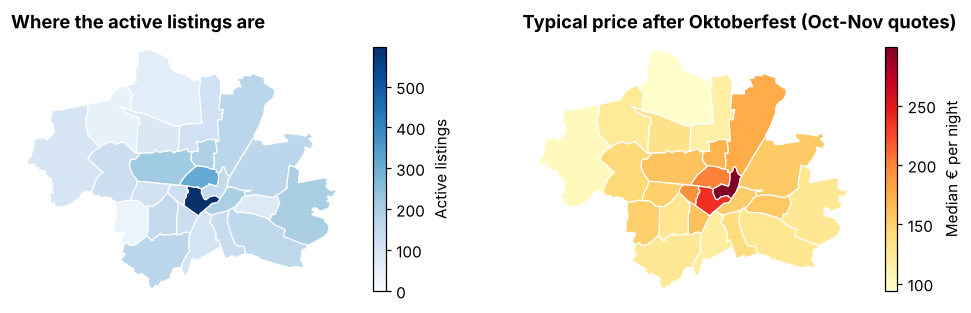

,active listings,median € / night (Oct-Nov)
neighbourhood_cleansed,,
Ludwigsvorstadt-Isarvorstadt,597,238
Maxvorstadt,310,201
Neuhausen-Nymphenburg,219,160
Tudering-Riem,202,128
Au-Haidhausen,200,154
Schwabing-West,192,169
Schwabing-Freimann,171,176
Bogenhausen,170,156


In [3]:
def draw_districts(ax, values, cmap, label_fmt, vmin=None, vmax=None):
    patches, colors = [], []
    for feature in districts["features"]:
        name = feature["properties"]["neighbourhood"]
        geom = feature["geometry"]
        polygons = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polygons:
            patches.append(Polygon(np.array(poly[0]), closed=True))
            colors.append(values.get(name, np.nan))
    pc = PatchCollection(patches, cmap=cmap, edgecolor="white", linewidth=0.8)
    pc.set_array(np.array(colors))
    pc.set_clim(vmin, vmax)
    ax.add_collection(pc)
    ax.autoscale_view()
    ax.set_aspect(1 / np.cos(np.radians(48.14)))
    ax.axis("off")
    return pc

active = listings[listings["active"]]
per_district = active.groupby("neighbourhood_cleansed").size()

quotes = listings.dropna(subset=["price_quote_price_per_night"]).copy()
quotes["checkin"] = pd.to_datetime(quotes["price_quote_checkin_date"])
quotes["nights"] = (pd.to_datetime(quotes["price_quote_checkout_date"]) - quotes["checkin"]).dt.days
quotes["ppn"] = quotes["price_quote_price_per_night"]
quotes = quotes[quotes["ppn"].between(15, 3000) & (quotes["nights"] <= 7) & (quotes["checkin"] < "2026-12-01")]
quotes["wiesn"] = quotes["checkin"] < WIESN_2026[1]   # the last Oktoberfest night is 3 -> 4 October
normal_price = quotes[~quotes["wiesn"]].groupby("neighbourhood_cleansed")["ppn"].median()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
pc = draw_districts(axes[0], per_district, "Blues", "{:.0f}", vmin=0)
fig.colorbar(pc, ax=axes[0], shrink=0.6, label="Active listings")
axes[0].set_title("Where the active listings are")
pc = draw_districts(axes[1], normal_price, "YlOrRd", "{:.0f}")
fig.colorbar(pc, ax=axes[1], shrink=0.6, label="Median € per night")
axes[1].set_title("Typical price after Oktoberfest (Oct-Nov quotes)")
fig.savefig(IMG / "01_districts.png")
plt.show()

summary = pd.DataFrame({"active listings": per_district, "median € / night (Oct-Nov)": normal_price}).sort_values("active listings", ascending=False)
summary.head(8).style.format({"active listings": "{:,.0f}", "median € / night (Oct-Nov)": "{:,.0f}"})

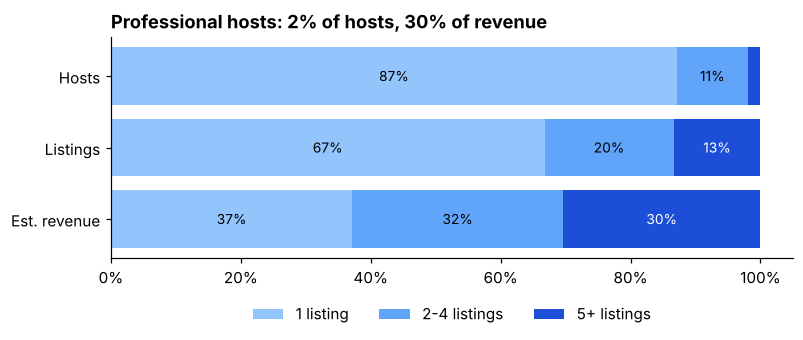

,hosts,listings,revenue
group,,,
1 listing,87.1%,66.8%,37.2%
2-4 listings,10.9%,19.9%,32.4%
5+ listings,2.0%,13.4%,30.4%


In [4]:
hosts = listings.groupby("host_id").agg(listings=("id", "size"), revenue=("estimated_revenue_l365d", "sum"))
hosts["group"] = pd.cut(hosts["listings"], [0, 1, 4, 10_000], labels=["1 listing", "2-4 listings", "5+ listings"])
share = hosts.groupby("group", observed=True).agg(hosts=("listings", "size"), listings=("listings", "sum"), revenue=("revenue", "sum"))
share = share / share.sum()

fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(3)
palette = [LIGHT_BLUE, "#60a5fa", BLUE]
for (group, row), color in zip(share.iterrows(), palette):
    vals = row[["hosts", "listings", "revenue"]].values
    ax.barh(["Hosts", "Listings", "Est. revenue"], vals, left=left, color=color, label=group)
    for i, v in enumerate(vals):
        if v > 0.06:
            ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if color == BLUE else "black")
    left += vals
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Professional hosts: 2% of hosts, 30% of revenue")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.savefig(IMG / "02_hosts.png")
plt.show()
share.style.format("{:.1%}")

- Listings cluster in the centre. **Ludwigsvorstadt-Isarvorstadt**, the district that contains the Oktoberfest grounds (Theresienwiese) and the main station, has by far the most.
- Outside Oktoberfest, the priciest nights are in the old town (Altstadt-Lehel, about 300 € median) and the central districts. Most outer districts cost 95-130 €, less than half as much.
- **Most hosts are individuals, but the money is more concentrated.** Hosts with five or more listings are about 2% of hosts but earn around 30% of Airbnb's estimated revenue in Munich.

## 3. The Oktoberfest effect

Three angles: demand (reviews), occupancy (the calendar), and price (the quotes).

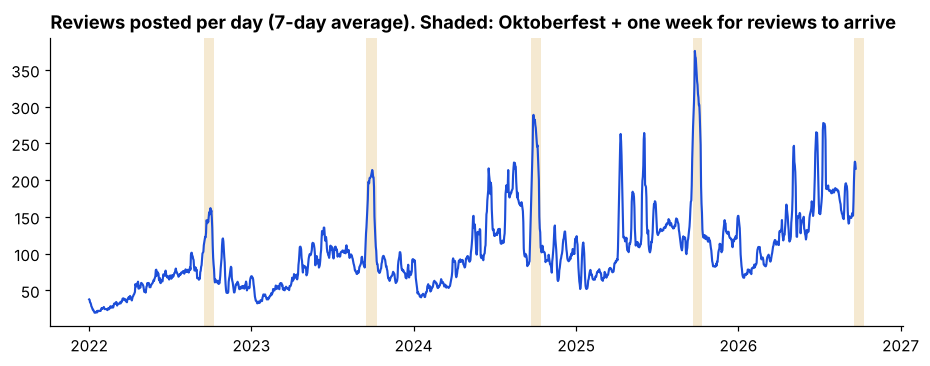

Reviews mentioning Oktoberfest/Wiesn: September 12.8%, October 8.1%, other months 0.2%


In [5]:
by_day = reviews.groupby("date").size()
fig, ax = plt.subplots(figsize=(10, 3.4))
smooth = by_day.asfreq("D", fill_value=0).rolling(7, center=True).mean()["2022":]
ax.plot(smooth.index, smooth, color=BLUE, lw=1.4)
for year in range(2022, 2027):
    start, end = wiesn(year)
    ax.axvspan(start, end + pd.Timedelta(days=7), color=GOLD, alpha=0.18, lw=0)
ax.set_title("Reviews posted per day (7-day average). Shaded: Oktoberfest + one week for reviews to arrive")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.savefig(IMG / "03_reviews_per_day.png")
plt.show()

core = reviews[reviews["lang"].isin(LANG_NAMES)]
mention = core.groupby(core["date"].dt.month)["oktoberfest"].mean()
print(f"Reviews mentioning Oktoberfest/Wiesn: September {mention[9]:.1%}, October {mention[10]:.1%}, "
      f"other months {core[~core['date'].dt.month.isin([9, 10])]['oktoberfest'].mean():.1%}")

Every year, review volume jumps around Oktoberfest. Guests review a few days after checking out, so the peak lands at the end of the festival and into October. **One in eight September reviews mentions the Oktoberfest or the Wiesn by name.**

Active listings in the occupancy analysis: 3,151


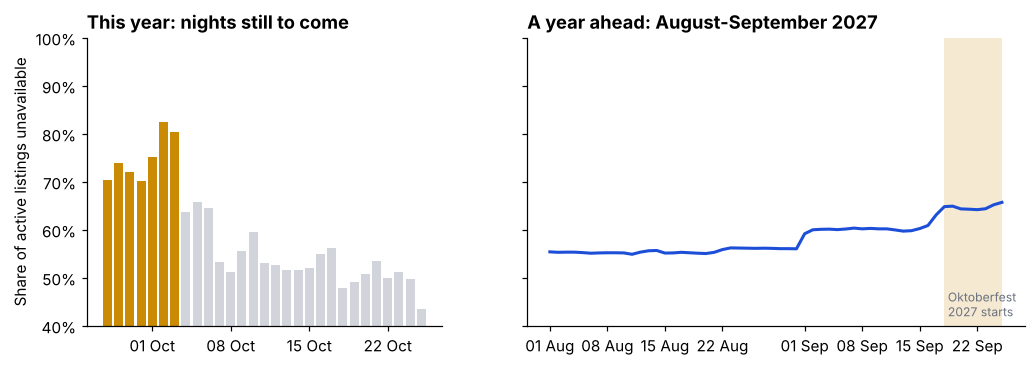

Remaining Oktoberfest nights: 75% unavailable vs 50% for 7-31 October
2027: 60% unavailable in early September vs 65% on the first Oktoberfest 2027 nights


In [6]:
cal = calendar.merge(listings[["id", "active"]], left_on="listing_id", right_on="id")
cal = cal[cal["active"]].copy()
cal["booked"] = cal["available"].eq("f")
always_blocked = cal.groupby("listing_id")["booked"].mean() > 0.98
cal = cal[~cal["listing_id"].isin(always_blocked[always_blocked].index)]
occ = cal.groupby("date")["booked"].mean()
print(f"Active listings in the occupancy analysis: {cal['listing_id'].nunique():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
w = occ["2026-09-27":"2026-10-25"]
axes[0].bar(w.index, w.values, color=[GOLD if d < WIESN_2026[1] else LIGHT for d in w.index], width=0.8)
axes[0].set_title("This year: nights still to come")
axes[0].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
n = occ["2027-08-01":]
axes[1].plot(n.index, n.values, color=BLUE, lw=2)
axes[1].axvspan(WIESN_2027[0], n.index.max(), color=GOLD, alpha=0.18, lw=0)
axes[1].text(WIESN_2027[0], 0.42, " Oktoberfest\n 2027 starts", fontsize=8, color=GREY)
axes[1].set_title("A year ahead: August-September 2027")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0.4, 1)
axes[0].set_ylabel("Share of active listings unavailable")
fig.savefig(IMG / "04_occupancy.png")
plt.show()

wiesn_nights = occ["2026-09-27":"2026-10-03"].mean()
after = occ["2026-10-07":"2026-10-31"].mean()
pre27 = occ["2027-09-01":"2027-09-14"].mean()
during27 = occ["2027-09-18":].mean()
print(f"Remaining Oktoberfest nights: {wiesn_nights:.0%} unavailable vs {after:.0%} for 7-31 October")
print(f"2027: {pre27:.0%} unavailable in early September vs {during27:.0%} on the first Oktoberfest 2027 nights")

"Unavailable" means booked *or* blocked by the host, so these are upper bounds on occupancy. The pattern is still clear:

- **The last Oktoberfest nights of 2026 are about 75% unavailable**, against about 50% for the rest of October, even though these nights were only a few days away when the data was scraped.
- **Oktoberfest 2027 may already be filling up a year in advance.** Unavailability steps up by about 5 points on exactly the opening weekend of Oktoberfest 2027. This is weaker evidence: there's a similar step on 1 September, probably hosts whose booking window opens month by month, so part of the 2027 pattern could be calendar settings rather than bookings.

**The price premium.** Comparing raw prices would be misleading. Listings still free during Oktoberfest may differ from the ones free in November, for example by being bigger or more central. So I fit a hedonic regression, comparing like with like:

`log(price per night) ~ Oktoberfest check-in + room type + log(guests) + bedrooms + district + rating + log(1 + reviews) + length of stay`

In [7]:
q = quotes.dropna(subset=["review_scores_rating"]).copy()
q["bedrooms"] = q["bedrooms"].fillna(1)
q["weekend_checkin"] = q["checkin"].dt.dayofweek >= 4
model = smf.ols("np.log(ppn) ~ wiesn + weekend_checkin + C(room_type) + np.log(accommodates) + bedrooms"
                " + C(neighbourhood_cleansed) + review_scores_rating + np.log1p(number_of_reviews) + nights",
                data=q).fit(cov_type="HC3")
premium = np.exp(model.params["wiesn[T.True]"]) - 1
lo, hi = np.exp(model.conf_int().loc["wiesn[T.True]"]) - 1
raw = q.groupby("wiesn")["ppn"].median()

print(f"Quotes used: {int(model.nobs):,} (Oktoberfest check-in: {q['wiesn'].sum():,}) | R² = {model.rsquared:.2f}")
print(f"Raw medians: {raw[True]:.0f} € during Oktoberfest vs {raw[False]:.0f} € after ({raw[True] / raw[False] - 1:+.0%})")
print(f"Like-for-like Oktoberfest premium: {premium:+.0%} (95% CI {lo:+.0%} to {hi:+.0%})")

Quotes used: 3,295 (Oktoberfest check-in: 1,801) | R² = 0.62
Raw medians: 280 € during Oktoberfest vs 160 € after (+76%)
Like-for-like Oktoberfest premium: +66% (95% CI +60% to +73%)


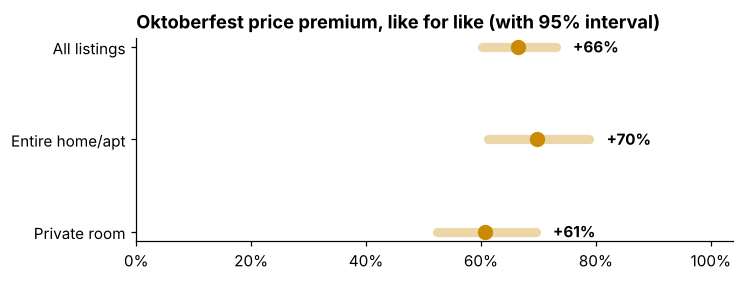

,quotes,premium,low,high
room type,,,,
Entire home/apt,2049,+70%,+61%,+79%
Private room,1208,+61%,+52%,+70%


In [8]:
by_type = []
for rt in ["Entire home/apt", "Private room"]:
    sub = q[q["room_type"] == rt]
    m = smf.ols("np.log(ppn) ~ wiesn + weekend_checkin + np.log(accommodates) + bedrooms + C(neighbourhood_cleansed)"
                " + review_scores_rating + np.log1p(number_of_reviews) + nights", data=sub).fit(cov_type="HC3")
    by_type.append({"room type": rt, "quotes": int(m.nobs), "premium": np.exp(m.params["wiesn[T.True]"]) - 1,
                    "low": np.exp(m.conf_int().loc["wiesn[T.True]", 0]) - 1,
                    "high": np.exp(m.conf_int().loc["wiesn[T.True]", 1]) - 1})
by_type = pd.DataFrame(by_type).set_index("room type")

fig, ax = plt.subplots(figsize=(7, 2.4))
rows = [("All listings", premium, lo, hi)] + [(i, r["premium"], r["low"], r["high"]) for i, r in by_type.iterrows()]
for y, (label, p, l, h) in enumerate(rows):
    ax.plot([l, h], [y, y], color=GOLD, lw=6, alpha=0.35, solid_capstyle="round")
    ax.plot(p, y, "o", color=GOLD, ms=9)
    ax.text(h + 0.03, y, f"{p:+.0%}", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlim(0, max(r[3] for r in rows) + 0.25)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Oktoberfest price premium, like for like (with 95% interval)")
fig.savefig(IMG / "05_premium.png")
plt.show()
by_type.style.format({"premium": "{:+.0%}", "low": "{:+.0%}", "high": "{:+.0%}"})

**A night during Oktoberfest costs about 66% more than a comparable night afterwards** (95% interval: +60% to +73%), after controlling for size, type, district, rating and the check-in weekday. The raw medians overstate it (+76%) because the listings still free during Oktoberfest differ from later ones in size, type and location. Whole apartments (+70%) and private rooms (+61%) are marked up by a similar amount, and their intervals overlap.

*Caveat:* each listing has only one quote, so this compares different listings, not the same listing on two dates. The regression controls for what's observable, but not for things like how good the photos are.

## 4. What guests say, in four languages

**Method.** `scripts/prepare_reviews.py` detects each review's language with `py3langid` (reviews under 15 characters are skipped). It then flags themes using keyword lists I wrote for German, English, French and Chinese, for example *sauber / clean / propre / 干净* for cleanliness. The lists handle common traps: *laut Beschreibung* ("according to the description") isn't noise, *pas de bruit* ("no noise") isn't a complaint, and *热情* ("warm-hearted") isn't heat. I spot-checked matches by hand in all four languages.

A keyword approach is transparent and easy to audit, but it isn't sentiment analysis. "Mentions cleanliness" means the topic came up, usually positively.

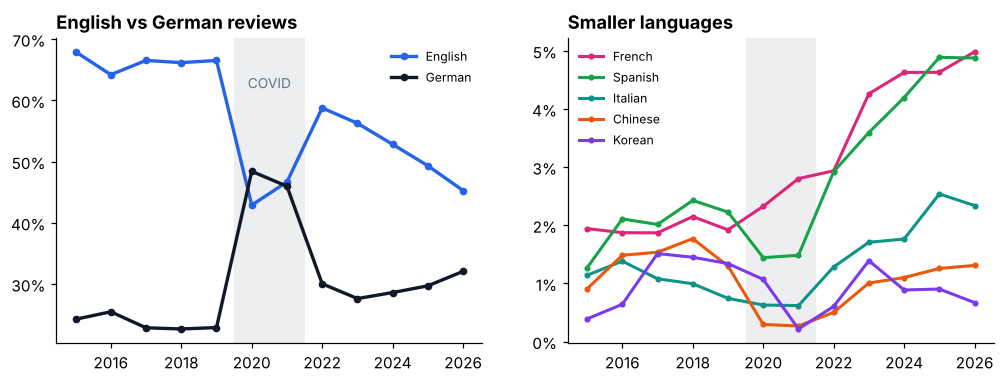

lang,en,de,fr,es,it,zh
year,,,,,,
2019,66.50,22.90,1.90,2.20,0.70,1.30
2021,46.70,46.00,2.80,1.50,0.60,0.30
2026,45.30,32.10,5.00,4.90,2.30,1.30


In [9]:
dated = reviews[reviews["lang"] != "short"].copy()
dated["year"] = dated["date"].dt.year
mix = pd.crosstab(dated["year"], dated["lang"], normalize="index").loc[2015:2026]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for lang in ["en", "de"]:
    axes[0].plot(mix.index, mix[lang], color=LANG_COLORS[lang], lw=2.2, marker="o", ms=4, label=LANG_NAMES[lang])
axes[0].set_title("English vs German reviews")
for lang, name in [("fr", "French"), ("es", "Spanish"), ("it", "Italian"), ("zh", "Chinese"), ("ko", "Korean")]:
    axes[1].plot(mix.index, mix[lang], lw=2, marker="o", ms=3, label=name,
                 color={**LANG_COLORS, "es": "#16a34a", "it": "#0d9488", "ko": "#7c3aed"}[lang])
axes[1].set_title("Smaller languages")
for ax in axes:
    ax.axvspan(2019.5, 2021.5, color=LIGHT, alpha=0.4, lw=0)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.legend(frameon=False, fontsize=8)
axes[0].text(2020.5, 0.62, "COVID", ha="center", color=GREY, fontsize=9)
fig.savefig(IMG / "06_language_mix.png")
plt.show()
(mix[["en", "de", "fr", "es", "it", "zh"]].loc[[2019, 2021, 2026]] * 100).round(1)

- **COVID turned Munich's Airbnb guests domestic.** German-language reviews jumped from 23% to 48% in 2020, while English fell from 66% to 43%.
- **Long-haul guests were slow to return.** Chinese reviews fell from 1.3-1.8% before COVID to 0.3% in 2020-21, and are only back to 1.3%. Korean shows a similar pattern.
- **Southern Europe is growing.** French, Spanish and Italian reviews have all more than doubled their share since 2019.

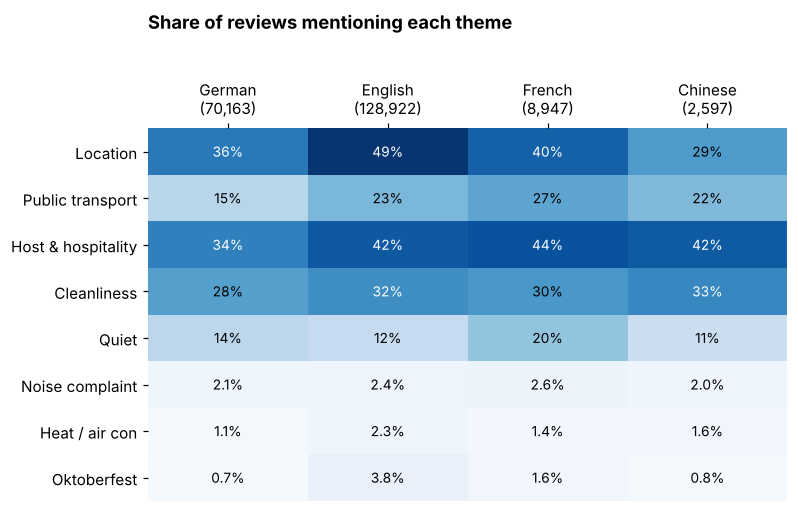

Median review length (characters): {'German': 148.0, 'English': 174.0, 'French': 152.0, 'Chinese': 53.0}


In [10]:
THEMES = {"location": "Location", "transport": "Public transport", "host": "Host & hospitality",
          "cleanliness": "Cleanliness", "quiet": "Quiet", "noise_complaint": "Noise complaint", "heat": "Heat / air con",
          "oktoberfest": "Oktoberfest"}
core = reviews[reviews["lang"].isin(LANG_NAMES)]
rates = core.groupby("lang")[list(THEMES)].mean().T.rename(index=THEMES, columns=LANG_NAMES)[["German", "English", "French", "Chinese"]]
counts = core["lang"].value_counts().rename(LANG_NAMES)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
im = ax.imshow(rates.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.5)
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        v = rates.iloc[i, j]
        ax.text(j, i, f"{v:.0%}" if v >= 0.1 else f"{v:.1%}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.3 else "black")
ax.set_xticks(range(4), [f"{c}\n({counts[c]:,})" for c in rates.columns])
ax.set_yticks(range(len(rates)), rates.index)
ax.xaxis.tick_top()
ax.spines[:].set_visible(False)
ax.set_title("Share of reviews mentioning each theme", pad=34)
fig.savefig(IMG / "07_themes.png")
plt.show()
print("Median review length (characters):", core.groupby("lang")["chars"].median().rename(LANG_NAMES).to_dict())

- **English speakers talk most about location (49%).** Many are first-time visitors, so being central is what they value.
- **French guests talk most about public transport (27%) and quiet (20%).** German guests mention transport least (15%): they know how the U-Bahn works and don't remark on it.
- **Chinese reviews are short** (a median of 53 characters, against about 150 for European languages, though Chinese packs more meaning per character). Even so, they mention cleanliness and the host as often as anyone.
- **Noise complaints are rare in every language**, at around 2%.

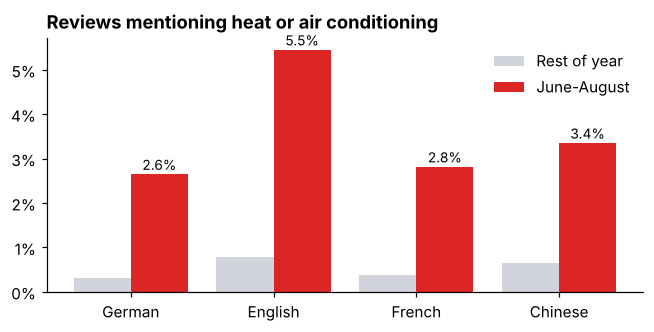

In [11]:
core = core.assign(summer=core["date"].dt.month.isin([6, 7, 8]))
heat = core.groupby(["lang", "summer"])["heat"].mean().unstack().rename(index=LANG_NAMES).loc[["German", "English", "French", "Chinese"]]

fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(len(heat))
ax.bar(x - 0.2, heat[False], width=0.4, color=LIGHT, label="Rest of year")
ax.bar(x + 0.2, heat[True], width=0.4, color=RED, label="June-August")
for i, v in enumerate(heat[True]):
    ax.text(i + 0.2, v + 0.001, f"{v:.1%}", ha="center", fontsize=9)
ax.set_xticks(x, heat.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Reviews mentioning heat or air conditioning")
ax.legend(frameon=False)
fig.savefig(IMG / "08_heat.png")
plt.show()

Air conditioning is rare in German homes. In summer, **one in eighteen English-language reviews brings up heat, fans or the lack of air con**, roughly double the rate in German reviews. German guests expect no air con, while international guests are surprised by it. For hosts, a fan and blackout blinds are a cheap way to avoid it showing up in reviews.

## 5. Takeaways

**For hosts**
1. **Oktoberfest is worth about +66% a night**, and there are early signs of bookings for 2027 already. Opening the calendar early likely pays off.
2. **Write the listing for its audience.** International guests care most about location and transport directions. Put the U-Bahn line and walking time to Marienplatz in the first lines.
3. **Prepare for summer heat** with a fan and blinds. Heat is a summer complaint that's specific to international guests.

**For the city**
4. **Professional hosts earn about 30% of the revenue from about 2% of hosts.** If regulation is the goal, that small group is where to focus.
5. **Only 0.5% of listings display a licence number**, so registration can't be checked from public data.

**Limitations:** one snapshot, scraped mid-festival. "Unavailable" includes host-blocked nights. The price premium compares similar listings, not the same listing. The theme analysis is keyword-based, and reviews in other languages (about 15%) aren't included in it.